In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import dataclasses
import pickle
import os

Mounted at /content/drive


In [ ]:
import sys, os

GIT_USER  = "JoeyTurn"
GIT_REPO  = "kernels_can_icl"

!git clone https://github.com/{GIT_USER}/{GIT_REPO}.git
!git clone https://github.com/dkarkada/expt-core.git

sys.path.insert(0, "/content/kernels_can_icl")
sys.path.insert(0, "/content/expt-core")

DATASETPATH = "/content/drive/MyDrive/datasets"
RESULTPATH  = "/content/drive/MyDrive/results"
os.environ["DATASETPATH"] = DATASETPATH
os.environ["RESULTPATH"]  = RESULTPATH
os.makedirs(DATASETPATH, exist_ok=True)
os.makedirs(RESULTPATH,  exist_ok=True)

Cloning into 'kernel_ICL'...
remote: Enumerating objects: 726, done.
remote: Counting objects: 100% (261/261), done.
remote: Compressing objects: 100% (172/172), done.
remote: Total 726 (delta 179), reused 164 (delta 85), pack-reused 465 (from 1)
Receiving objects: 100% (726/726), 43.46 MiB | 19.68 MiB/s, done.
Resolving deltas: 100% (373/373), done.
Cloning into 'modelscape'...
remote: Enumerating objects: 234, done.
remote: Counting objects: 100% (234/234), done.
remote: Compressing objects: 100% (156/156), done.
remote: Total 234 (delta 142), reused 168 (delta 76), pack-reused 0 (from 0)
Receiving objects: 100% (234/234), 218.78 KiB | 4.86 MiB/s, done.
Resolving deltas: 100% (142/142), done.
Cloning into 'expt-core'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (58/58), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 58 (delta 28), reused 47 (delta 17), pack-reused 0 (from 0)
Receiving objects: 100% (58/58), 16.11 KiB | 16.11 MiB/s, do

In [ ]:
from misc import rcsetup
rcsetup()
from pathlib import Path

outdir = Path("/content/drive/MyDrive/picl/figs/appx/")
outdir.mkdir(parents=True, exist_ok=True)

rank=143  learnable=0.6400  v_perp^2=0.3527
homoskedastic Tr = rank*v_perp^2 = 50.4   heteroskedastic C = Tr[Sig^+ M] = 71.0


saved


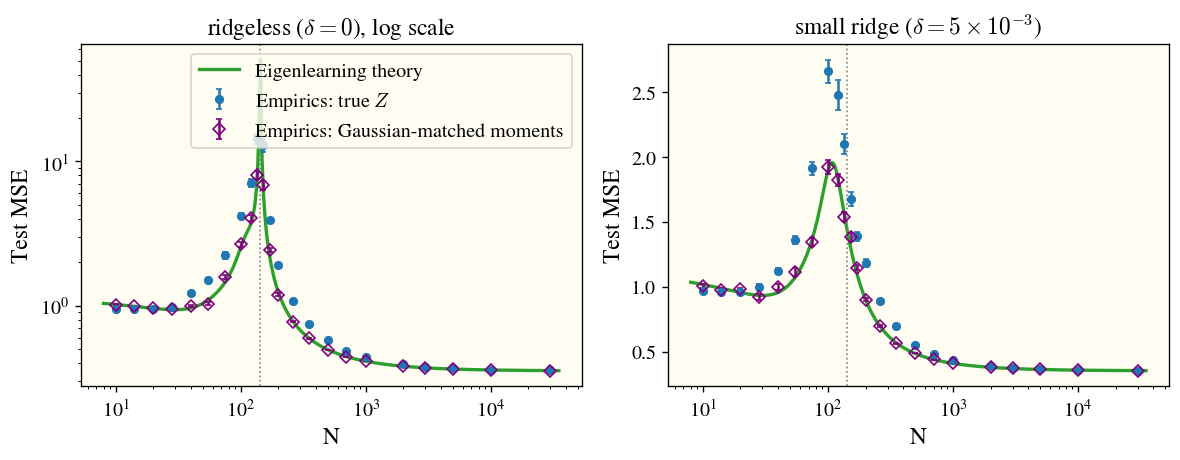

In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import brentq

rng = np.random.default_rng(1)

L = 8
D = 2 * L + 1
betas = np.array([0.0615, 0.4, 1.2, 1.5385])
c0, c1, c2 = 1.0, 0.05, 0.01
iu0, iu1 = np.triu_indices(D, k=1)
P = 1 + D + D + D * (D - 1) // 2          # 171

def sample(n, rng):
    b = rng.choice(betas, size=n)
    X = rng.standard_normal((n, L))
    Xq = rng.standard_normal((n, 1))
    Z = np.concatenate([X, b[:, None] * X, Xq], axis=1)
    return Z, b * Xq[:, 0]

def feats(Z):
    n = Z.shape[0]
    return np.concatenate([
        np.full((n, 1), np.sqrt(c0)), np.sqrt(c1) * Z,
        np.sqrt(c2 / 2) * Z ** 2, np.sqrt(c2) * Z[:, iu0] * Z[:, iu1]], axis=1)

# ---------- exact moments under the true Z-distribution ---------------------
def zinfo(a):
    if a < L:        return (0, a)
    elif a < 2 * L:  return (1, a - L)
    else:            return (0, L)

scales, bdeg, expo = [], [], []
def add(s, d, e): scales.append(s); bdeg.append(d); expo.append(e)
add(np.sqrt(c0), 0, np.zeros(L + 1, dtype=int))
for a in range(D):
    d, v = zinfo(a); e = np.zeros(L + 1, dtype=int); e[v] = 1; add(np.sqrt(c1), d, e)
for a in range(D):
    d, v = zinfo(a); e = np.zeros(L + 1, dtype=int); e[v] = 2; add(np.sqrt(c2/2), 2*d, e)
for a, b in zip(iu0, iu1):
    da, va = zinfo(a); db, vb = zinfo(b)
    e = np.zeros(L + 1, dtype=int); e[va] += 1; e[vb] += 1
    add(np.sqrt(c2), da + db, e)
scales = np.array(scales); bdeg = np.array(bdeg); expo = np.array(expo)

bmom = np.array([np.mean(betas ** k) for k in range(8)])      # E[b^k]
gmom = np.array([1., 0., 1., 0., 3., 0., 15.])                # E[X^k]
Eb = bmom[1]
wmom = np.array([np.mean((betas - Eb) ** 2 * betas ** k) for k in range(8)])

def moment_matrix(beta_table, extra_q_pow):
    Mm = np.outer(scales, scales) * beta_table[bdeg[:, None] + bdeg[None, :]]
    for v in range(L + 1):
        add_pow = extra_q_pow if v == L else 0
        Mm *= gmom[expo[:, v][:, None] + expo[:, v][None, :] + add_pow]
    return Mm

Sig = moment_matrix(bmom, 0)                 # E[phi phi^T]
Mhet = moment_matrix(wmom, 2)                # E[f_perp^2 phi phi^T]

e_q = np.zeros(L + 1, dtype=int); e_q[L] = 1
u = scales * bmom[bdeg + 1]
for v in range(L + 1):
    u *= gmom[expo[:, v] + e_q[v]]
f2 = bmom[2]

lam, V = np.linalg.eigh(Sig)
order = np.argsort(lam)[::-1]; lam, V = lam[order], V[:, order]
keep = lam > 1e-12 * lam[0]; rank = int(keep.sum())
proj = V.T @ u
lam_k = lam[keep]
v_vec = proj[keep] / np.sqrt(lam_k)
v2_k = v_vec ** 2
v_perp2 = f2 - v2_k.sum()
Mt_diag = np.einsum('ia,ab,bi->i', V.T[keep], Mhet, V[:, keep])
C_exact = float(np.sum(Mt_diag / lam_k))
print(f"rank={rank}  learnable={v2_k.sum():.4f}  v_perp^2={v_perp2:.4f}")
print(f"homoskedastic Tr = rank*v_perp^2 = {rank*v_perp2:.1f}   heteroskedastic C = Tr[Sig^+ M] = {C_exact:.1f}")

# ---------- theory -----------------------------------------------------------
def theory(n, delta, mode):
    if delta == 0 and n >= rank:
        kap, Lrn = 0.0, np.ones(rank)
    else:
        g = lambda k: np.sum(lam_k / (lam_k + k)) + delta / k - n
        kap = brentq(g, 1e-20, 1e12, maxiter=500)
        Lrn = lam_k / (lam_k + kap)
    sumL2 = float(np.sum(Lrn ** 2))
    if n - sumL2 <= 0: return np.inf
    E0 = n / (n - sumL2)
    bias_in = float(np.sum((1 - Lrn) ** 2 * v2_k))
    if mode == "homo":
        return E0 * (bias_in + v_perp2)
    trM = float(np.sum(Mt_diag * lam_k / (lam_k + kap) ** 2)) if kap > 0 else C_exact
    return E0 * bias_in + v_perp2 + trM / (n - sumL2)

# ---------- empirics (closed-form risk per trial) ----------------------------
def run_trueZ(N, delta, rng):
    Z, y = sample(N, rng); F = feats(Z)
    if delta == 0: w, *_ = np.linalg.lstsq(F, y, rcond=None)
    else:          w = np.linalg.solve(F.T @ F + delta * np.eye(P), F.T @ y)
    return f2 - 2 * u @ w + w @ Sig @ w

def run_gaussFeat(N, delta, rng):
    G = rng.standard_normal((N, rank))
    Psi = G * np.sqrt(lam_k)
    y = G @ v_vec + np.sqrt(v_perp2) * rng.standard_normal(N)
    if delta == 0: w, *_ = np.linalg.lstsq(Psi, y, rcond=None)
    else:          w = np.linalg.solve(Psi.T @ Psi + delta * np.eye(rank), Psi.T @ y)
    return float(np.sum((v_vec - np.sqrt(lam_k) * w) ** 2)) + v_perp2

def sweep(runner, Ns, delta):
    means, errs = [], []
    for N in Ns:
        trials = int(np.clip(60000 // N, 10, 60))
        e = np.array([runner(N, delta, rng) for _ in range(trials)])
        means.append(e.mean()); errs.append(e.std() / np.sqrt(trials))
    return np.array(means), np.array(errs)

Ns = np.array([10, 14, 20, 28, 40, 55, 75, 100, 120, 135, 152, 170, 200,
               260, 350, 500, 700, 1000, 2000, 3000, 5000, 10000, 30000])
n_th = np.unique(np.round(np.geomspace(8, 35000, 320)).astype(int))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, delta, ttl, logy in [
        (axes[0], 0.0,  r"ridgeless ($\delta=0$), log scale", True),
        (axes[1], 5e-3, r"small ridge ($\delta=5\times10^{-3}$)", False)]:
    mT, sT = sweep(run_trueZ, Ns, delta)
    mF, sF = sweep(run_gaussFeat, Ns, delta)
    nt = n_th[n_th != rank] if delta == 0 else n_th
    # ax.plot(nt, [theory(n, delta, "het") for n in nt], color="tab:red", lw=2,
    #         label="heteroskedastic theory (for true $Z$)")
    ax.plot(nt, [theory(n, delta, "homo") for n in nt], color="tab:green", lw=2,
            label=r"Eigenlearning theory", )
    ax.errorbar(Ns, mT, yerr=sT, fmt="o", ms=4.5, capsize=2, color="tab:blue",
                zorder=4, label="Empirics: true $Z$")
    ax.errorbar(Ns, mF, yerr=sF, fmt="D", ms=5, capsize=2, mfc="none",
                color="purple", zorder=4,
                label="Empirics: Gaussian-matched moments")
    ax.axvline(rank, color="gray", ls=":", lw=1)
    ax.set_xscale("log")
    if logy: ax.set_yscale("log")
    ax.set_xlabel("N", fontsize=14); ax.set_ylabel("Test MSE", fontsize=14); ax.set_title(ttl, fontsize=14)
    if ax == axes[0]:
        ax.legend(fontsize=12)
    # print(f"--- delta={delta}")
    # for N, a, b_ in zip(Ns, mT, mF):
    #     nn = N + 1 if (delta == 0 and N == rank) else N
    #     print(f"  N={N:6d}  trueZ={a:9.3f} (het={theory(nn,delta,'het'):8.3f})"
    #           f"   gaussFeat={b_:9.3f} (eq9={theory(nn,delta,'homo'):8.3f})")

# fig.suptitle(f"KICL, d=1, T=4, L=8 — exact spectrum (rank={rank}): true-$Z$ vs Gaussian-matched empirics, "
#              "each with its theory curve")
fig.tight_layout()
# fig.savefig("/home/claude/kicl_fig5.png", dpi=150)
fig.savefig("/content/drive/MyDrive/picl/figs/appx/onedim_eigenlearning_failure.pdf", dpi=130, bbox_inches="tight")
print("saved")